# **Deteksi Promosi Judi Online pada Komentar YouTube Berbahasa Indonesia Menggunakan Support Vector Machine dan Multilayer Perceptron dengan Normalisasi Character Obfuscation**

Link Dataset :https://www.kaggle.com/datasets/yaemico/judionline

# **1. IMPORT LIBRARY**

In [2]:
import pandas as pd
import numpy as np
import re
import string
import time
import unicodedata
from collections import Counter

import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

import nltk
nltk.download('stopwords')

from nltk.corpus import stopwords


!pip install Sastrawi -q

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory


from sklearn.model_selection import (
train_test_split,
cross_val_score
)

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.svm import LinearSVC

from sklearn.neural_network import MLPClassifier

from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
classification_report,
confusion_matrix
)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


# **2. LOAD DATASET**

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
file_path = "/content/drive/Shareddrives/project_Machine Learning/data_komentar.csv"

data = pd.read_csv(file_path)

In [5]:
print("Shape Dataset:", data.shape)
print("\nKolom Dataset:")
print(data.columns)

Shape Dataset: (10230, 9)

Kolom Dataset:
Index(['video_id', 'title', 'channel_name', 'tanggal', 'author', 'komentar',
       'label', 'komentar_clean', 'predicted_label'],
      dtype='object')


In [6]:
data.head()

,video_id,title,channel_name,tanggal,author,komentar,label,komentar_clean,predicted_label
0,f8UEkmYXlzA,SKAKMAT AHOK,Pandji Pragiwaksono,1.745.412.234.123.970,TerranceNoelle-o9i,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆...,1,makin yakin abis baca review lain tentang 𝐒𝐆𝐈𝟖𝟖 .,0
1,XI8K0-_kbHc,GAK NYANGKA BISA BEGINI! PENGENDARA DIJALAN SA...,Jejelogy,1.739.601.493.342.000,deraatvexplorerriders.2113,Paling suka model H2 😍🔥,0,suka model h2,0
2,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Drift...,Garasi Drift,1.739.772.479.808.090,risqokurniadi7208,Mobilnya udah hancur 🥺,0,mobilnya udah hancur,0
3,QpXcKzQInXg,Review Mobil Drift Seharga Super Car | BRZ V8 ...,Garasi Drift,1.738.825.556.100.780,LorrianeDotson,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,1,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin sultan,1
4,nZoNbiwP2ZE,Akhirnya Selesai Subaru Crosstrek Family Drift...,Garasi Drift,1.739.858.865.953.920,Elpoco7365,Semoga lekas recover mobilnya mas Dipo,0,semoga lekas recover mobilnya mas dipo,0


# **3. DATA SELECTION**

In [7]:
data_main = data[['komentar', 'label', 'komentar_clean', 'tanggal' ]].copy()

print("Data Awal:")
data_main.head()

Data Awal:


,komentar,label,komentar_clean,tanggal
0,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆...,1,makin yakin abis baca review lain tentang 𝐒𝐆𝐈𝟖𝟖 .,1.745.412.234.123.970
1,Paling suka model H2 😍🔥,0,suka model h2,1.739.601.493.342.000
2,Mobilnya udah hancur 🥺,0,mobilnya udah hancur,1.739.772.479.808.090
3,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,1,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin sultan,1.738.825.556.100.780
4,Semoga lekas recover mobilnya mas Dipo,0,semoga lekas recover mobilnya mas dipo,1.739.858.865.953.920


# **4. DATA CLEANING**

In [8]:
print("Shape Awal :", data_main.shape)

print("\nMissing Values:")
print(data_main[['komentar','label']].isnull().sum())

print("\nDuplicate Comments:")
print(data_main.duplicated(subset=['komentar']).sum())

Shape Awal : (10230, 4)

Missing Values:
komentar    0
label       0
dtype: int64

Duplicate Comments:
1229


In [9]:
data_main.dropna(subset=['komentar', 'label'], inplace=True)

In [10]:
data_main['label'] = data_main['label'].astype(int)

In [11]:
data_main = data_main[data_main['label'].isin([0, 1])]

In [12]:
data_main.drop_duplicates(subset=['komentar'], inplace=True)

In [13]:
data_main.reset_index(drop=True, inplace=True)
print("Shape Setelah Cleaning:", data_main.shape)

Shape Setelah Cleaning: (9001, 4)


# **5. EXPLORATORY DATA ANALYSIS (EDA)**

**5.1 Visualisasi Distribusi Label Dataset**

Di bagian EDA pertama, kami visualisasikan distribusi label menggunakan sns.countplot. Dari output yang terlihat, label 0 atau normal ada 6.018 data dan label 1 atau judol ada 2.983 data. Dataset ini imbalanced, makanya di train test split nanti kami pakai stratify.

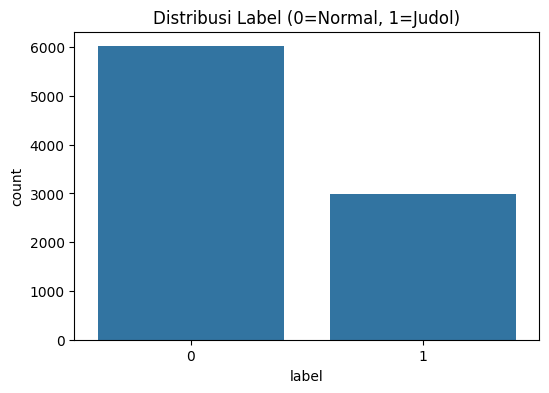

In [14]:
plt.figure(figsize=(6,4))
sns.countplot(x='label', data=data_main)
plt.title("Distribusi Label (0=Normal, 1=Judol)")
plt.show()

In [15]:
print("Distribusi Label:")
print(data_main['label'].value_counts())

Distribusi Label:
label
0    6018
1    2983
Name: count, dtype: int64


**5.2 Analisis Panjang Komentar**

Selanjutnya kami buat kolom comment_length dari panjang karakter tiap komentar, lalu divisualisasikan dengan boxplot. Hasilnya jelas terlihat — bahwa median panjang komentar judol lebih tinggi dibanding komentar normal, artinya komentar judol secara umum lebih panjang. Banyak juga outlier di label 1 yang menunjukkan ada spam dengan isi sangat panjang dan repetitif.

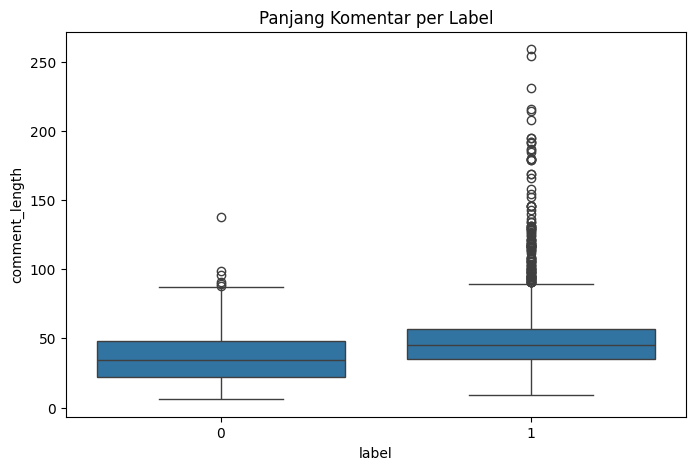

In [16]:
data_main['comment_length'] = data_main['komentar'].astype(str).apply(len)

plt.figure(figsize=(8,5))
sns.boxplot(x='label', y='comment_length', data=data_main)
plt.title("Panjang Komentar per Label")
plt.show()

**5.3 Analisis Character Obfuscation**

In [17]:
judol_comments = data_main[data_main['label'] == 1]['komentar']

has_unicode = judol_comments.apply(lambda x: bool(re.search(r'[^\x00-\x7F]', str(x))))

has_leet = judol_comments.apply(lambda x: bool(
re.search(r'[0-9]', str(x))
)
)

print("POLA OBFUSCATION")

print(
f"Unicode non-ascii : "
f"{has_unicode.sum()}"
)

print(
f"Mengandung angka : "
f"{has_leet.sum()}"
)

POLA OBFUSCATION
Unicode non-ascii : 1875
Mengandung angka : 1665


5.3.1 Visualisasi Obfuscation

,Jenis,Jumlah
0,Unicode Non-ASCII,1875
1,Mengandung Angka,1665


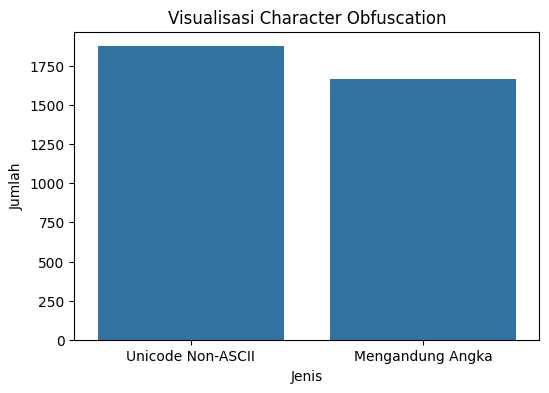

In [18]:
obfuscation_df = pd.DataFrame({
    'Jenis': [
        'Unicode Non-ASCII',
        'Mengandung Angka'
    ],
    'Jumlah': [
        has_unicode.sum(),
        has_leet.sum()
    ]
})

display(obfuscation_df)

plt.figure(figsize=(6,4))

sns.barplot(
    data=obfuscation_df,
    x='Jenis',
    y='Jumlah'
)

plt.title('Visualisasi Character Obfuscation')

plt.show()

**5.4 Analisis Spam Keyword**

In [19]:
spam_keywords = [
'alexis17',
'sgi88',
'manut88',
'weton88',
'slot',
'gacor',
'maxwin',
'wd',
'jp'
]

print("SPAM KEYWORD")

for keyword in spam_keywords:

    count = ( data_main['komentar'].astype(str).str.lower().str.contains(keyword).sum())

    print(f"{keyword}: {count}")

SPAM KEYWORD
alexis17: 456
sgi88: 0
manut88: 1
weton88: 20
slot: 14
gacor: 84
maxwin: 45
wd: 59
jp: 34


**5.5 WORDCLOUD KOMENTAR**

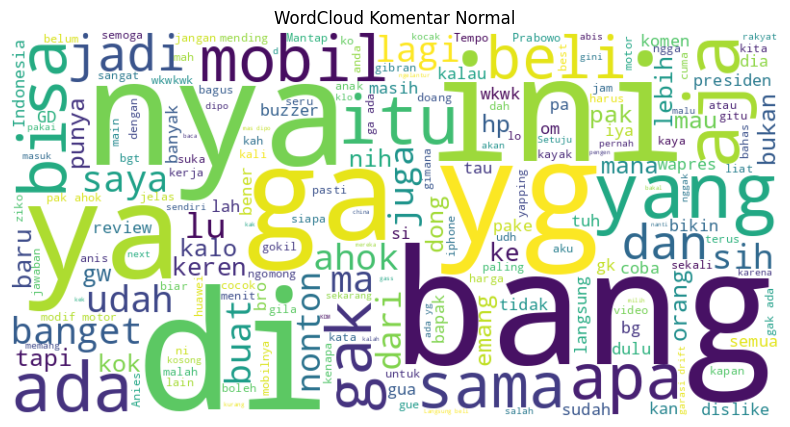

In [20]:
normal_text = " ".join(
    data_main[data_main['label'] == 0]['komentar'].astype(str)
)

wordcloud_normal = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(normal_text)

plt.figure(figsize=(10,5))

plt.imshow(wordcloud_normal, interpolation='bilinear')

plt.axis('off')

plt.title('WordCloud Komentar Normal')

plt.show()

Berdasarkan Gambar, komentar normal didominasi oleh kata-kata yang berkaitan dengan isi video dan interaksi antar pengguna, seperti bang, gak, mobil, yang, dan bisa. Hal ini menunjukkan bahwa sebagian besar komentar normal berisi tanggapan, opini, maupun diskusi terkait konten video yang ditonton.

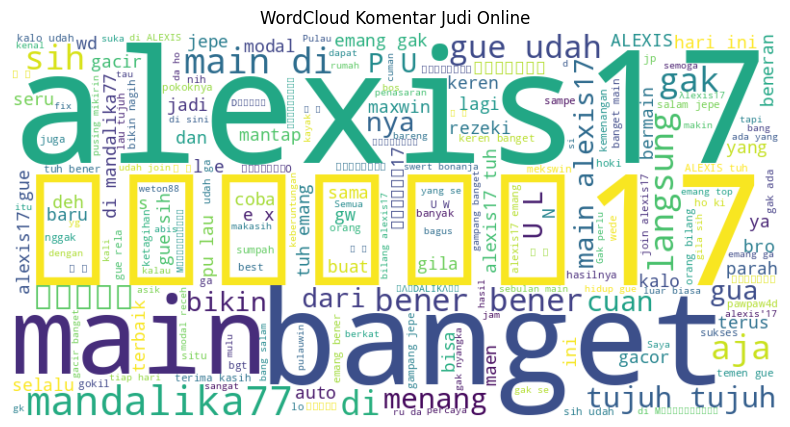

In [21]:
judol_text = " ".join(
    data_main[data_main['label'] == 1]['komentar'].astype(str)
)

wordcloud_judol = WordCloud(
    width=800,
    height=400,
    background_color='white'
).generate(judol_text)

plt.figure(figsize=(10,5))

plt.imshow(wordcloud_judol, interpolation='bilinear')

plt.axis('off')

plt.title('WordCloud Komentar Judi Online')

plt.show()

Berdasarkan Gambar, komentar promosi judi online didominasi oleh nama situs tertentu serta kata-kata promosi seperti alexis17, gacor, dan mandalika77. Kemunculan kata-kata tersebut secara berulang menunjukkan adanya pola promosi yang khas pada komentar judol dan dapat menjadi indikator penting dalam proses klasifikasi.

**5.6 TOP FREQUENT WORDS**

TOP 15 KATA PALING SERING MUNCUL


,Word,Frequency
0,di,852
1,banget,550
2,bang,549
3,gak,526
4,ini,524
5,nya,469
6,alexis17,455
7,main,425
8,yg,414
9,udah,390


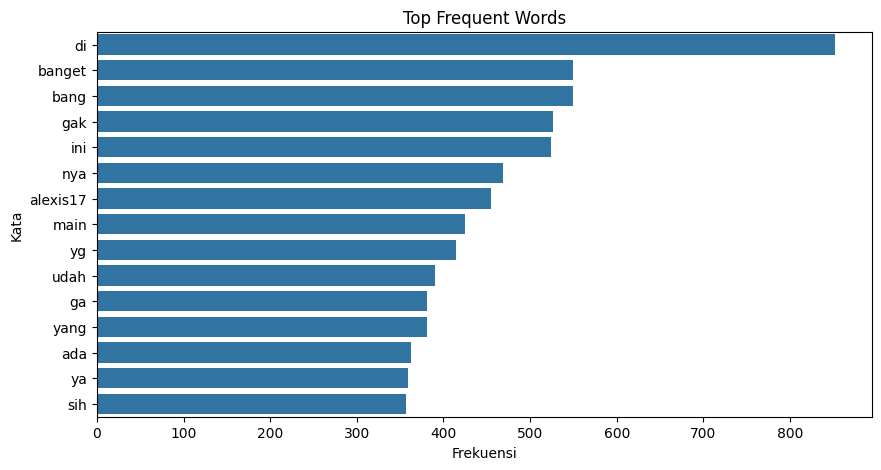

In [22]:
from collections import Counter

all_comments = " ".join(
    data_main['komentar'].astype(str).str.lower()
)

words = re.findall(r'\w+', all_comments)

word_counts = Counter(words)

top_words = pd.DataFrame(
    word_counts.most_common(15),
    columns=['Word', 'Frequency']
)

print("TOP 15 KATA PALING SERING MUNCUL")
display(top_words)

plt.figure(figsize=(10,5))

sns.barplot(
    data=top_words,
    x='Frequency',
    y='Word'
)

plt.title('Top Frequent Words')
plt.xlabel('Frekuensi')
plt.ylabel('Kata')

plt.show()

**5.7 ANALISIS BIGRAM**

TOP 15 BIGRAM


,Bigram,Frequency
0,alexis 17,189
1,main di,92
2,bener bener,80
3,gue udah,78
4,tujuh tujuh,74
5,main alexis17,64
6,emang gak,63
7,gak ada,62
8,keren banget,60
9,di mandalika77,55


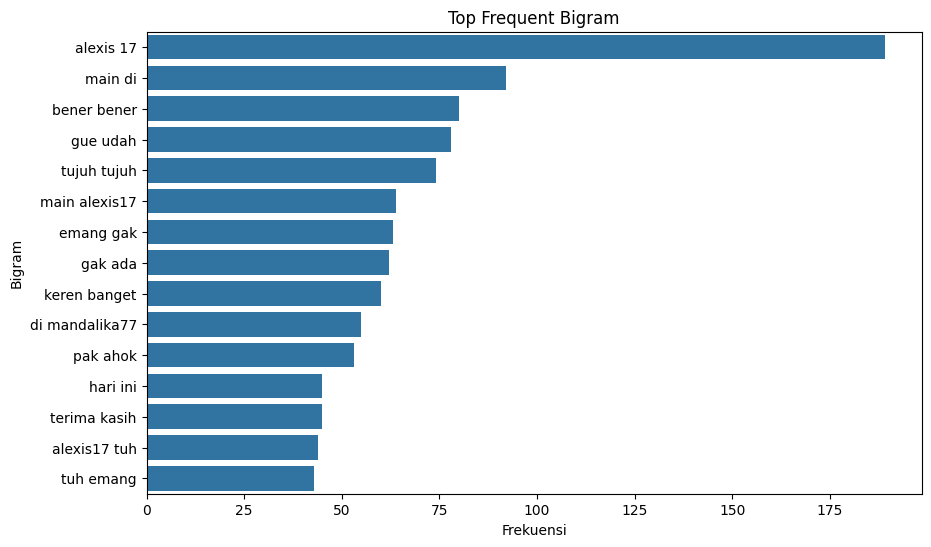

In [23]:
from sklearn.feature_extraction.text import CountVectorizer

bigram_vectorizer = CountVectorizer(
    ngram_range=(2,2),
    stop_words=None
)

bigram_matrix = bigram_vectorizer.fit_transform(
    data_main['komentar'].astype(str)
)

bigram_sum = bigram_matrix.sum(axis=0)

bigram_freq = [
    (
        word,
        bigram_sum[0, idx]
    )
    for word, idx
    in bigram_vectorizer.vocabulary_.items()
]

bigram_freq = sorted(
    bigram_freq,
    key=lambda x: x[1],
    reverse=True
)[:15]

bigram_df = pd.DataFrame(
    bigram_freq,
    columns=['Bigram', 'Frequency']
)

print("TOP 15 BIGRAM")
display(bigram_df)

plt.figure(figsize=(10,6))

sns.barplot(
    data=bigram_df,
    x='Frequency',
    y='Bigram'
)

plt.title('Top Frequent Bigram')
plt.xlabel('Frekuensi')
plt.ylabel('Bigram')

plt.show()

Parsing Tanggal

In [24]:
def parse_tanggal(val):
    val = str(val).strip()
    if '-' in val:
        return pd.to_datetime(val, utc=True)
    else:
        val_clean = val.replace('.', '').split(',')[0]
        ts = float(val_clean)
        panjang = len(val_clean)
        try:
            if panjang >= 16:
                return pd.to_datetime(ts, unit='us', utc=True)
            elif panjang == 15:
                return pd.to_datetime(int(ts), unit='ns', utc=True)
            elif panjang >= 13:
                return pd.to_datetime(ts, unit='ms', utc=True)
            else:
                return pd.to_datetime(ts, unit='s', utc=True)
        except Exception:
            return pd.NaT

data_main['tanggal_dt'] = data_main['tanggal'].apply(parse_tanggal)

data_main = data_main[data_main['tanggal_dt'].dt.year >= 2025].reset_index(drop=True)
data_main['tanggal_dt'] = data_main['tanggal_dt'].dt.tz_localize(None)
data_main['hari'] = data_main['tanggal_dt'].dt.to_period('D')


Tren Kemunculan Komentar per Hari

label
0    5396
1    2848
Name: count, dtype: int64


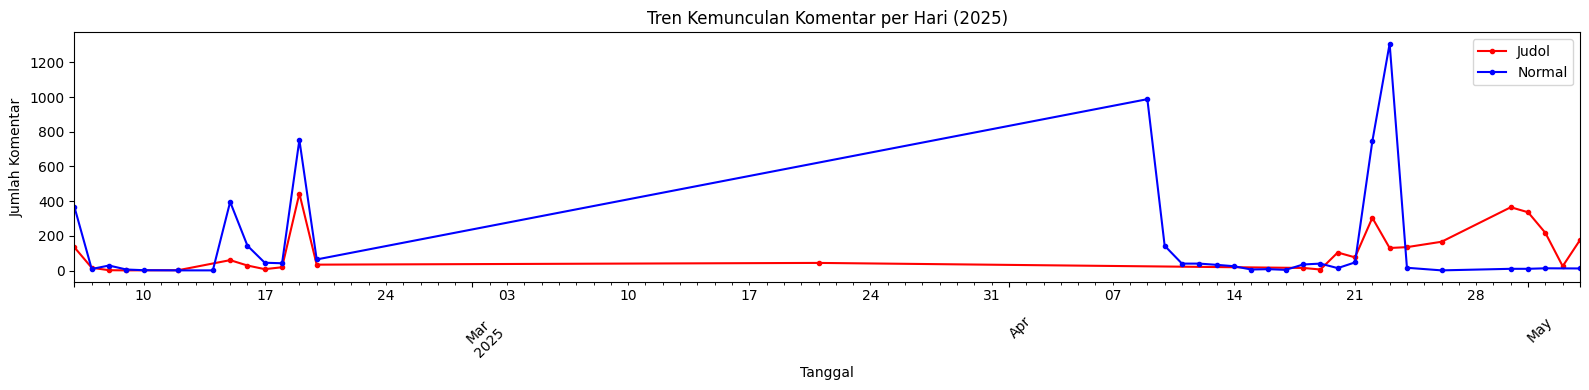

In [25]:
data_2025 = data_main[data_main['tanggal_dt'].dt.year == 2025].copy()
print(data_2025['label'].value_counts())

judol_comments = data_2025[data_2025['label'] == 1]
normal_comments = data_2025[data_2025['label'] == 0]

tren_judol = judol_comments.groupby(judol_comments['tanggal_dt'].dt.to_period('D')).size()
tren_normal = normal_comments.groupby(normal_comments['tanggal_dt'].dt.to_period('D')).size()

plt.figure(figsize=(16, 4))
tren_judol.plot(kind='line', marker='o', markersize=3, color='red', label='Judol')
tren_normal.plot(kind='line', marker='o', markersize=3, color='blue', label='Normal')
plt.title('Tren Kemunculan Komentar per Hari (2025)')
plt.xlabel('Tanggal')
plt.ylabel('Jumlah Komentar')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# **6. SETUP STOPWORD & STEMMER**

In [26]:
stop_words = set(
stopwords.words('indonesian')
)

factory = StemmerFactory()

stemmer = factory.create_stemmer()

Sebelum preprocessing, kami siapkan dua tools. Stopword dari NLTK bahasa Indonesia untuk hapus kata tidak bermakna, dan Stemmer dari Sastrawi khusus Bahasa Indonesia untuk ubah kata berimbuhan ke bentuk dasarnya. Kedua tools ini dipakai di semua skenario preprocessing.

# **7. STANDARD PREPROCESSING**

Fungsi standard_preprocessing ini memproses teks dalam beberapa langkah seperti lowercase, hapus URL, hapus mention dan hashtag, hapus tanda baca, hapus karakter non-alfanumerik, hapus spasi berlebih, tokenisasi, stopword removal, dan terakhir stemming.

In [27]:
def standard_preprocessing(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'@\w+|#\w+', '', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'[^\w\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    tokens = text.split()
    tokens = [word for word in tokens if word not in stop_words]
    tokens = [stemmer.stem(word) for word in tokens]
    return " ".join(tokens)

Kelemahannya, Unicode stylized text seperti '𝐒𝐆𝐈𝟖𝟖' akan hilang begitu saja karena tidak ada normalisasi obfuscation di sini.

# **8. ADVANCED PREPROCESSING**

In [28]:
def merge_spaced_letters(text):
    pattern = r'\b(?:[a-zA-Z0-9]\s+){2,}[a-zA-Z0-9]\b'
    matches = re.findall(pattern, text)

    for match in matches:
        merged = match.replace(" ", "")
        text = text.replace(match, merged)

    return text

def advanced_preprocessing(text):
    text = str(text).lower()

    text = unicodedata.normalize('NFKD', text)
    text = text.encode('ascii', 'ignore').decode('utf-8', 'ignore')

    text = re.sub(r'http\S+|www\S+|https\S+', ' ', text)

    text = re.sub(r'[☯✌░🔥⚡❤⭐•🚩🥺😍😂🤣👎👏💯✨🎯💸💰💥🤑🔞]', ' ', text)

    number_map = {
        'nol': '0',
        'kosong': '0',
        'satu': '1',
        'dua': '2',
        'tiga': '3',
        'empat': '4',
        'lima': '5',
        'enam': '6',
        'tujuh': '7',
        'delapan': '8',
        'sembilan': '9'
    }

    for word, num in number_map.items():
        text = re.sub(rf'\b{word}\b', num, text)

    text = merge_spaced_letters(text)

    symbol_map = {
        '@': 'a',
        '$': 's',
        '!': 'i'
    }

    for sym, repl in symbol_map.items():
        text = text.replace(sym, repl)

    text = re.sub(r'(?<=\D)0(?=\D)', 'o', text)
    text = re.sub(r'(?<=\D)1(?=\D)', 'i', text)
    text = re.sub(r'(?<=\D)3(?=\D)', 'e', text)
    text = re.sub(r'(?<=\D)4(?=\D)', 'a', text)
    text = re.sub(r'(?<=\D)5(?=\D)', 's', text)

    text = text.replace('@', ' ')
    text = text.replace('#', ' ')

    text = text.translate(str.maketrans('', '', string.punctuation))

    text = re.sub(r'[^\w\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text).strip()

    tokens = text.split()

    tokens = [word for word in tokens if word not in stop_words]

    tokens = [stemmer.stem(word) for word in tokens]

    return " ".join(tokens)

# **9. DATASET CLEAN PREPROCESSING**

In [29]:
def dataset_clean_preprocessing(text):

    text = str(text).lower()

    text = re.sub(
        r'\s+',
        ' ',
        text
    ).strip()

    tokens = text.split()

    tokens = [
        word
        for word in tokens
        if word not in stop_words
    ]

    tokens = [
        stemmer.stem(word)
        for word in tokens
    ]

    return " ".join(tokens)

# **10. TERAPKAN PREPROCESSING**

In [30]:
data_main['clean_standard'] = (data_main['komentar'].apply(standard_preprocessing))

In [31]:
data_main['clean_advanced'] = (data_main['komentar'].apply(advanced_preprocessing))

In [32]:
data_main['clean_dataset'] = (data_main['komentar_clean'].apply(dataset_clean_preprocessing))

In [33]:
data_main[['komentar','clean_standard','clean_advanced','clean_dataset']].head(30)

,komentar,clean_standard,clean_advanced,clean_dataset
0,Makin yakin abis baca review lain tentang ✌✌𝐒𝐆...,abis baca review,abis baca review sgi88,abis baca review
1,Paling suka model H2 😍🔥,suka model h2,suka model h2,suka model h2
2,Mobilnya udah hancur 🥺,mobil udah hancur,mobil udah hancur,mobil udah hancur
3,░𝙈𝘼𝙉𝙐𝙏88░benar2 bikin aku jadi sultan,88 benar2 bikin sultan,manut88benar2 bikin sultan,88 benar2 bikin sultan
4,Semoga lekas recover mobilnya mas Dipo,moga lekas recover mobil mas dipo,moga lekas recover mobil mas dipo,moga lekas recover mobil mas dipo
5,pantes tongkrongan maen alexis17,pantes tongkrong maen alexis17,pantes tongkrong maen alexis17,pantes tongkrong maen alexis17
6,gua udah ga bisa bayangin hidup tanpa ALEXIS-1...,gua udah ga bayangin hidup alexis17 sih,gua udah ga bayangin hidup alexis17 sih,gua udah ga bayangin hidup alexis-17 sih
7,langsung percaya lihat hasilnya,langsung percaya lihat hasil,langsung percaya lihat hasil,langsung percaya lihat hasil
8,orang bilang alexis17 tuh miracle banget !,orang bilang alexis17 tuh miracle banget,orang bilang alexis17 tuh miracle banget i,orang bilang alexis17 tuh miracle banget
9,Yapping mulu anjir kagak ada jawaban sistemati...,yapping mulu anjir kagak sistematis realistis,yapping mulu anjir kagak sistematis realistis,yapping mulu anjir kagak sistematis realistis


# **11. SIAPKAN TARGET & FITUR**

In [34]:
y = data_main['label']

X_standard = data_main['clean_standard']

X_advanced = data_main['clean_advanced']

X_dataset = data_main['clean_dataset']

Pada tahap ini dilakukan pemisahan antara fitur dan target. Label digunakan sebagai target klasifikasi, sedangkan komentar hasil preprocessing digunakan sebagai fitur input. Ketiga dataset tersebut kemudian digunakan pada proses pembagian data, ekstraksi fitur TF-IDF, dan pelatihan model.

# **12. TRAIN TEST SPLIT**

In [35]:
X_train_std, X_test_std, y_train_std, y_test_std = train_test_split(
    X_standard,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [36]:
X_train_adv, X_test_adv, y_train_adv, y_test_adv = train_test_split(
    X_advanced,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [37]:
X_train_ds, X_test_ds, y_train_ds, y_test_ds = train_test_split(
    X_dataset,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

Dataset dibagi 80:20 menggunakan train_test_split. Terlihat di kode, kami jalankan tiga kali — untuk X_standard, X_advanced, dan X_dataset secara terpisah. Parameter penting di sini ada dua: stratify=y agar proporsi kelas terjaga karena dataset imbalanced, dan random_state=42 agar hasilnya reproducible. Hasilnya 7.200 data training dan 1.801 data testing untuk masing-masing skenario.

# **13. TF-IDF VECTORIZATION**

In [38]:
tfidf_std = TfidfVectorizer(ngram_range=(1,2),max_features=10000)

X_train_std_tfidf = tfidf_std.fit_transform(X_train_std)
X_test_std_tfidf = tfidf_std.transform(X_test_std)

In [39]:
tfidf_adv = TfidfVectorizer(ngram_range=(1,2),max_features=10000)

X_train_adv_tfidf = tfidf_adv.fit_transform(X_train_adv)
X_test_adv_tfidf = tfidf_adv.transform(X_test_adv)

In [40]:
tfidf_ds = TfidfVectorizer(ngram_range=(1,2),max_features=10000)

X_train_ds_tfidf = tfidf_ds.fit_transform(X_train_ds)
X_test_ds_tfidf = tfidf_ds.transform(X_test_ds)

# **14. TRAINING SVM**

In [41]:
start = time.time()
svm_std = LinearSVC()

svm_std.fit(X_train_std_tfidf, y_train_std)
runtime_svm_std = time.time() - start
y_pred_svm_std = svm_std.predict(X_test_std_tfidf)

In [42]:
start = time.time()
svm_adv = LinearSVC()

svm_adv.fit(X_train_adv_tfidf,y_train_adv)
runtime_svm_adv = time.time() - start
y_pred_svm_adv = svm_adv.predict(X_test_adv_tfidf)

In [43]:
start = time.time()
svm_ds = LinearSVC()

svm_ds.fit(X_train_ds_tfidf,y_train_ds)
runtime_svm_ds = time.time() - start
y_pred_svm_ds = svm_ds.predict(X_test_ds_tfidf)

In [44]:
print("RUNTIME SVM")

print("Standard :", runtime_svm_std)
print("Advanced :", runtime_svm_adv)
print("Dataset Clean :", runtime_svm_ds)

RUNTIME SVM
Standard : 0.025171995162963867
Advanced : 0.0225369930267334
Dataset Clean : 0.020974159240722656


Berdasarkan hasil pengukuran runtime, seluruh skenario preprocessing pada model SVM memiliki waktu komputasi yang sangat cepat, yaitu sekitar 0,02 detik. Preprocessing Advanced menghasilkan runtime tercepat sebesar 0,0206 detik, diikuti Standard sebesar 0,0220 detik dan Dataset Clean sebesar 0,0219 detik. Perbedaan waktu yang dihasilkan relatif kecil, sehingga ketiga skenario preprocessing tidak memberikan pengaruh yang signifikan terhadap kecepatan proses klasifikasi pada model SVM.

# **15. EVALUASI SVM**

In [45]:
print("SVM STANDARD")
print(classification_report(y_test_std, y_pred_svm_std))

print("\nSVM ADVANCED")
print(classification_report(y_test_adv, y_pred_svm_adv))

print("\nSVM DATASET CLEAN")
print(classification_report(y_test_ds, y_pred_svm_ds))

SVM STANDARD
              precision    recall  f1-score   support

           0       0.97      0.98      0.98      1079
           1       0.96      0.94      0.95       570

    accuracy                           0.97      1649
   macro avg       0.97      0.96      0.96      1649
weighted avg       0.97      0.97      0.97      1649


SVM ADVANCED
              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1079
           1       0.98      0.97      0.97       570

    accuracy                           0.98      1649
   macro avg       0.98      0.98      0.98      1649
weighted avg       0.98      0.98      0.98      1649


SVM DATASET CLEAN
              precision    recall  f1-score   support

           0       0.97      0.98      0.97      1079
           1       0.96      0.94      0.95       570

    accuracy                           0.97      1649
   macro avg       0.97      0.96      0.96      1649
weighted avg       0.97     

SVM Standard

Berdasarkan hasil evaluasi, model SVM dengan Standard Preprocessing memperoleh accuracy sebesar 96,22%, precision sebesar 95,87%, recall sebesar 92,63%, dan F1-score sebesar 94,22% pada kelas komentar judol. Hasil tersebut menunjukkan bahwa model sudah mampu mengklasifikasikan komentar dengan baik, namun masih terdapat beberapa komentar judol yang belum berhasil terdeteksi sehingga nilai recall masih relatif lebih rendah dibandingkan precision.

SVM Advanced

Model SVM dengan Advanced Preprocessing menghasilkan performa terbaik dengan accuracy sebesar 97,83%, precision sebesar 97,94%, recall sebesar 95,48%, dan F1-score sebesar 96,69% pada kelas komentar judol. Peningkatan nilai recall dan F1-score menunjukkan bahwa normalisasi character obfuscation berhasil membantu model mengenali komentar promosi judi online yang sebelumnya sulit dideteksi akibat penggunaan Unicode stylized text, simbol dekoratif, maupun substitusi karakter.

SVM Dataset Clean

Model SVM dengan Dataset Clean Preprocessing memperoleh accuracy sebesar 96,56%, precision sebesar 96,38%, recall sebesar 93,13%, dan F1-score sebesar 94,73%. Hasil tersebut lebih baik dibandingkan Standard Preprocessing, namun masih berada di bawah Advanced Preprocessing. Hal ini menunjukkan bahwa proses cleaning bawaan dataset mampu membantu meningkatkan kualitas data, tetapi belum cukup efektif dalam menangani pola character obfuscation yang kompleks.

# **16. Feature Importance SVM**

In [46]:
feature_names = tfidf_adv.get_feature_names_out()

coefficients = svm_adv.coef_.flatten()

feature_importance = pd.DataFrame({
    'feature': feature_names,
    'coef': coefficients
})

top_judol = feature_importance.sort_values(
    by='coef',
    ascending=False
).head(15)

top_normal = feature_importance.sort_values(
    by='coef',
    ascending=True
).head(15)

print("TOP KATA JUDOL")
display(top_judol)

print("\nTOP KATA NORMAL")
display(top_normal)

TOP KATA JUDOL


,feature,coef
315,alexis17,7.735950
7644,mandalika77,4.747594
9098,sgi88,3.643530
8690,pulauwin,3.544951
8816,rezeki,3.273488
9833,weton88,2.941819
8575,pluto88,2.402576
8683,pulau777,2.386910
6836,jepe,2.369703
892,berkah99,2.236485



TOP KATA NORMAL


,feature,coef
7032,kau,-1.620701
7717,mas,-0.959441
805,beli,-0.926309
231,ahok,-0.923609
3450,dislike,-0.890843
8620,presiden,-0.838060
6642,hp,-0.824913
6048,golput main,-0.743283
4264,episode,-0.742105
5497,gd,-0.729863


Analisis Feature importance dilakukan untuk mengetahui kata-kata yang palinh berpengaruh terhadap keputusan klasifikasi model SVM. kata seperti alexis17, mandalika77, pulauwin, dan sgi88 memiliki bobot positif tertinggi sehingga menjadi indikator kuat komentar promosi judi online. Sebaliknya, kata seperti presiden, mobil, dan dislike memiliki bobot negatif sehingga lebih identik dengan komentar normal. Hasil ini menunjukkan bahwa model berhasil mempelajari pola kata yang relevan dalam membedakan komentar judol dan komentar normal.

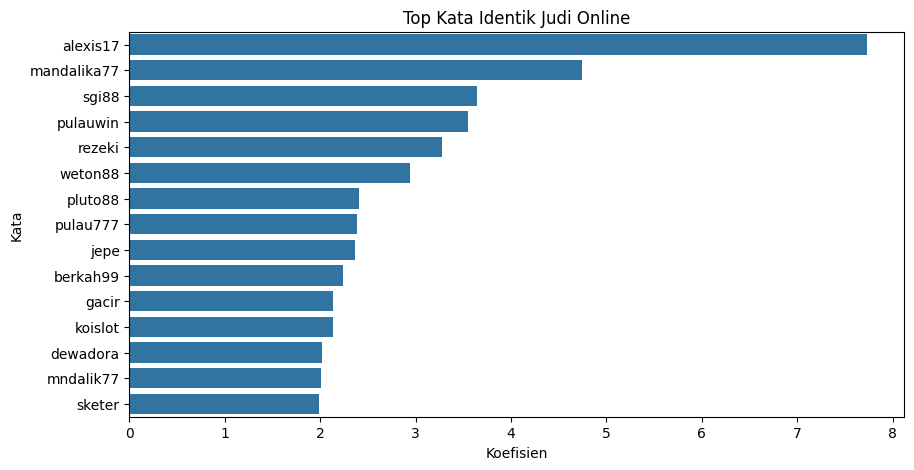

In [47]:
plt.figure(figsize=(10,5))

sns.barplot(
    x='coef',
    y='feature',
    data=top_judol
)

plt.title('Top Kata Identik Judi Online')

plt.xlabel('Koefisien')

plt.ylabel('Kata')

plt.show()

# **17. CONFUSION MATRIX SVM**

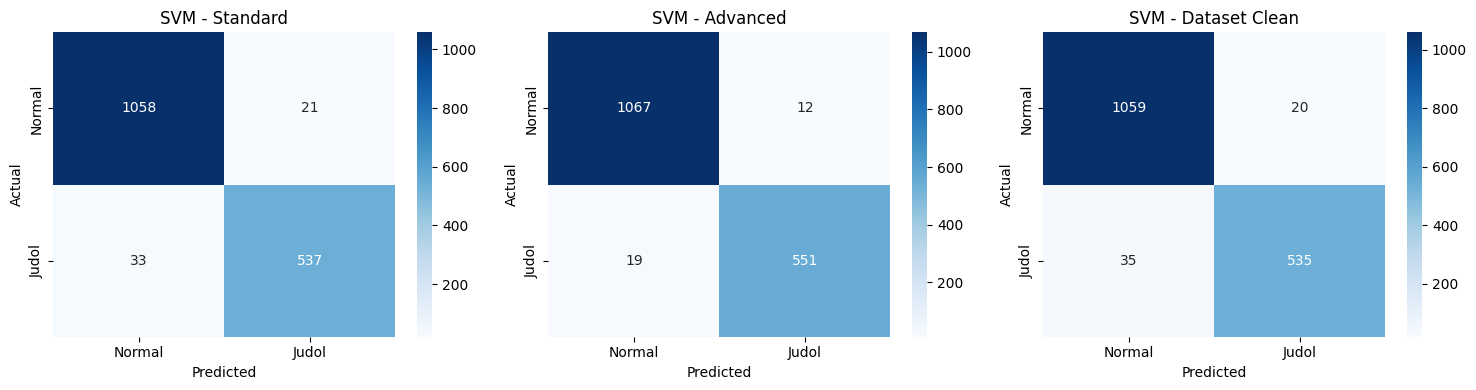

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))

cm_std_svm = confusion_matrix(
    y_test_std,
    y_pred_svm_std
)

sns.heatmap(
    cm_std_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol'],
    ax=axes[0]
)

axes[0].set_title('SVM - Standard')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

cm_adv_svm = confusion_matrix(
    y_test_adv,
    y_pred_svm_adv
)

sns.heatmap(
    cm_adv_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol'],
    ax=axes[1]
)

axes[1].set_title('SVM - Advanced')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

cm_ds_svm = confusion_matrix(
    y_test_ds,
    y_pred_svm_ds
)

sns.heatmap(
    cm_ds_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol'],
    ax=axes[2]
)

axes[2].set_title('SVM - Dataset Clean')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

Dari confusion matrix SVM yang terlihat di sini, kita bisa bandingkan langsung ketiga skenario. SVM Standard: 1.179 benar normal, 554 benar judol, 25 false positive, 43 false negative. SVM Advanced meningkat signifikan: 1.192 benar normal, 570 benar judol, false positive turun jadi 12, false negative turun jadi 27. SVM Dataset Clean ada di tengah: 1.181, 558, 23, dan 39. Jadi Advanced jelas yang terbaik.

# **18. Error Analysis SVM**

In [49]:
errors_svm_std = pd.DataFrame({
    'comment': X_test_std.reset_index(drop=True),
    'actual': y_test_std.reset_index(drop=True),
    'predicted': y_pred_svm_std
})

errors_svm_std = errors_svm_std[
    errors_svm_std['actual'] != errors_svm_std['predicted']
]

print("Jumlah Error SVM Standard:", len(errors_svm_std))

display(errors_svm_std.head(5))


errors_svm_adv = pd.DataFrame({
    'comment': X_test_adv.reset_index(drop=True),
    'actual': y_test_adv.reset_index(drop=True),
    'predicted': y_pred_svm_adv
})

errors_svm_adv = errors_svm_adv[
    errors_svm_adv['actual'] != errors_svm_adv['predicted']
]

print("\nJumlah Error SVM Advanced:", len(errors_svm_adv))

display(errors_svm_adv.head(5))


errors_svm_ds = pd.DataFrame({
    'comment': X_test_ds.reset_index(drop=True),
    'actual': y_test_ds.reset_index(drop=True),
    'predicted': y_pred_svm_ds
})

errors_svm_ds = errors_svm_ds[
    errors_svm_ds['actual'] != errors_svm_ds['predicted']
]

print("\nJumlah Error SVM Dataset Clean:", len(errors_svm_ds))

display(errors_svm_ds.head(5))

Jumlah Error SVM Standard: 54


,comment,actual,predicted
14,gede modal sparepart susah,0,1
82,joe biden versi lokal,0,1
112,kasih tau buka jelas,0,1
146,0727 dadak tajir,1,0
153,ngeri sepupu gue smp aja tau p u l a u w i n,1,0



Jumlah Error SVM Advanced: 31


,comment,actual,predicted
14,gede modal sparepart susah,0,1
180,lengkap kalo chery bikin dealer pangkal bun,1,0
222,baik sih gak pelit pelit,1,0
247,yg db 10 aja kebel udah db 12 aja,1,0
274,bahagia hakiki,0,1



Jumlah Error SVM Dataset Clean: 55


,comment,actual,predicted
14,gede modal sparepart susah,0,1
66,main aman hasil jawab,1,0
82,joe biden versi lokal,0,1
112,kasih tau buka jelas,0,1
153,ngeri sepupu gue smp aja tau p u l a u w i n,1,0


Dari error analysis, SVM Standard salah di 68 komentar, Advanced hanya 39, Dataset Clean 62. Kalau dilihat contohnya — komentar 'tetangga gw sore main p u l a u w i n' dengan actual judol diprediksi normal, karena karakternya dipisah spasi jadi model tidak mengenalinya. Sebaliknya komentar normal yang nyebut kata 'sultan' atau 'pulauwin' diprediksi judol karena model menganggapnya sebagai indikator spam.

# **19. TRAINING MLP**

In [50]:
start = time.time()
mlp_std = MLPClassifier(

    hidden_layer_sizes=(128, 64),

    activation='relu',

    solver='adam',

    max_iter=300,

    random_state=42

)

mlp_std.fit(
    X_train_std_tfidf,
    y_train_std
)

runtime_mlp_std = time.time() - start
y_pred_mlp_std = mlp_std.predict(
    X_test_std_tfidf
)

In [51]:
start = time.time()
mlp_adv = MLPClassifier(

    hidden_layer_sizes=(128, 64),

    activation='relu',

    solver='adam',

    max_iter=300,

    random_state=42

)

mlp_adv.fit(
    X_train_adv_tfidf,
    y_train_adv
)

runtime_mlp_adv = time.time() - start
y_pred_mlp_adv = mlp_adv.predict(
    X_test_adv_tfidf
)

In [52]:
start = time.time()
mlp_ds = MLPClassifier(

    hidden_layer_sizes=(128, 64),

    activation='relu',

    solver='adam',

    max_iter=300,

    random_state=42

)

mlp_ds.fit(
    X_train_ds_tfidf,
    y_train_ds
)

runtime_mlp_ds = time.time() - start
y_pred_mlp_ds = mlp_ds.predict(
    X_test_ds_tfidf
)

In [53]:
print("RUNTIME MLP")

print("Standard :", runtime_mlp_std)
print("Advanced :", runtime_mlp_adv)
print("Dataset Clean :", runtime_mlp_ds)

RUNTIME MLP
Standard : 70.36897850036621
Advanced : 31.057604789733887
Dataset Clean : 40.0342903137207


# **20. EVALUASI MLP**

In [54]:
print("MLP STANDARD")

print(
classification_report(
y_test_std,
y_pred_mlp_std
)
)

print("\nMLP ADVANCED")

print(
classification_report(
y_test_adv,
y_pred_mlp_adv
)
)

print("\nMLP DATASET CLEAN")

print(
classification_report(
y_test_ds,
y_pred_mlp_ds
)
)

MLP STANDARD
              precision    recall  f1-score   support

           0       0.97      0.96      0.96      1079
           1       0.92      0.94      0.93       570

    accuracy                           0.95      1649
   macro avg       0.94      0.95      0.94      1649
weighted avg       0.95      0.95      0.95      1649


MLP ADVANCED
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      1079
           1       0.95      0.96      0.95       570

    accuracy                           0.97      1649
   macro avg       0.96      0.97      0.96      1649
weighted avg       0.97      0.97      0.97      1649


MLP DATASET CLEAN
              precision    recall  f1-score   support

           0       0.97      0.96      0.96      1079
           1       0.92      0.94      0.93       570

    accuracy                           0.95      1649
   macro avg       0.94      0.95      0.94      1649
weighted avg       0.95     

# **21. Analisis bobot fitur sederhana**

In [55]:
positive_weights = mlp_adv.coefs_[0].mean(axis=1)

feature_names = tfidf_adv.get_feature_names_out()

weights = mlp_adv.coefs_[0].mean(axis=1)

feature_importance_mlp = pd.DataFrame({
    'feature': feature_names,
    'weight': weights
})

top_judol_mlp = feature_importance_mlp.sort_values(
    by='weight',
    ascending=False
).head(15)

top_normal_mlp = feature_importance_mlp.sort_values(
    by='weight',
    ascending=True
).head(15)

print("TOP KATA JUDOL")
display(top_judol_mlp)

print("\nTOP KATA NORMAL")
display(top_normal_mlp)

TOP KATA JUDOL


,feature,weight
4652,ga,0.036515
4991,gak,0.032165
254,aja,0.029331
657,banget,0.028685
9581,tuh,0.028211
4084,emang,0.027905
626,bang,0.026583
9888,ya,0.026471
9144,sih,0.026318
7310,langsung,0.026111



TOP KATA NORMAL


,feature,weight
315,alexis17,-0.013426
9509,timbang,-0.012920
9731,upload bg,-0.012735
9468,terimakasih upload,-0.012683
6638,hoki777,-0.011686
7551,main,-0.011068
8345,old,-0.010720
7644,mandalika77,-0.010559
9413,tawar,-0.010365
8606,populer,-0.010273


Berdasarkan hasil analisis, model MLP memberikan bobot yang berbeda pada setiap fitur sebagai bagian dari proses pembelajaran jaringan saraf. Bobot tersebut menunjukkan kontribusi fitur terhadap keputusan model dan tidak merepresentasikan frekuensi kemunculan kata. Oleh karena itu, hasil analisis bobot fitur MLP dapat berbeda dengan hasil analisis frekuensi kata pada tahap EDA karena model mempelajari hubungan non-linear antar fitur selama proses pelatihan.

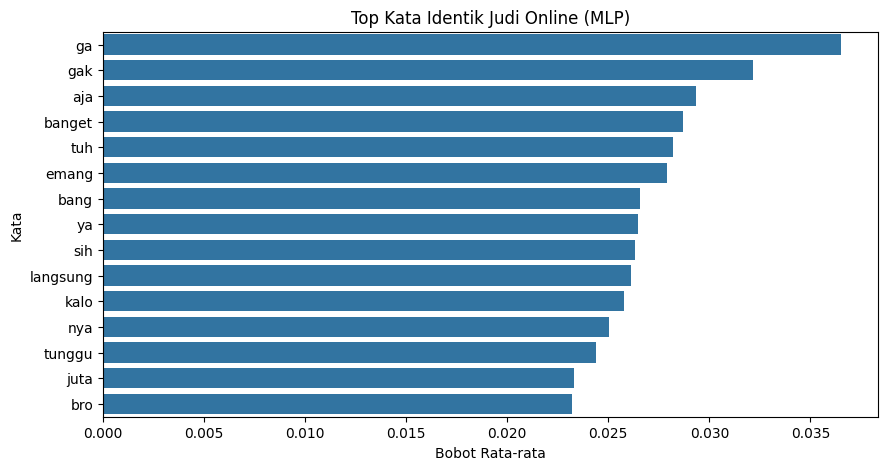

In [56]:
# Visualisasi Top Kata Judol MLP

plt.figure(figsize=(10,5))

sns.barplot(
    x='weight',
    y='feature',
    data=top_judol_mlp
)

plt.title('Top Kata Identik Judi Online (MLP)')
plt.xlabel('Bobot Rata-rata')
plt.ylabel('Kata')

plt.show()

# **22. CONFUSION MATRIX MLP**

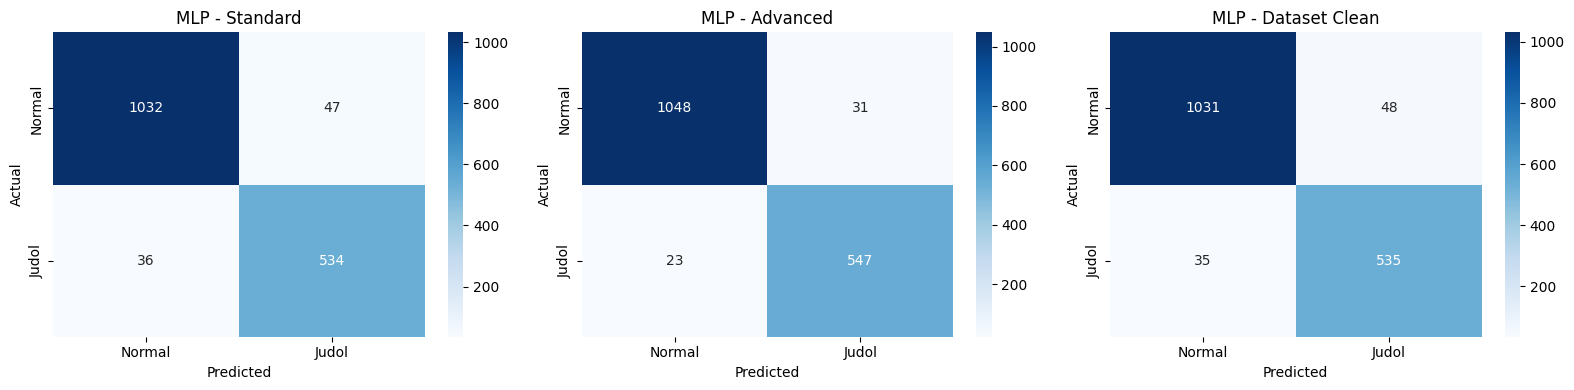

In [57]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

cm_std_mlp = confusion_matrix(
    y_test_std,
    y_pred_mlp_std
)

sns.heatmap(
    cm_std_mlp,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol'],
    ax=axes[0]
)

axes[0].set_title('MLP - Standard')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

cm_adv_mlp = confusion_matrix(
    y_test_adv,
    y_pred_mlp_adv
)

sns.heatmap(
    cm_adv_mlp,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol'],
    ax=axes[1]
)

axes[1].set_title('MLP - Advanced')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

#Dataset Clean
cm_ds_mlp = confusion_matrix(
    y_test_ds,
    y_pred_mlp_ds
)

sns.heatmap(
    cm_ds_mlp,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol'],
    ax=axes[2]
)
axes[2].set_title('MLP - Dataset Clean')
axes[2].set_xlabel('Predicted')
axes[2].set_ylabel('Actual')

plt.tight_layout()
plt.show()

model MLP pada skenario Standard Preprocessing berhasil mengklasifikasikan 1.147 komentar normal dan 552 komentar judol dengan benar. Namun, masih terdapat 57 komentar normal yang salah diprediksi sebagai komentar judol (false positive) serta 45 komentar judol yang salah diprediksi sebagai komentar normal (false negative).

pada skenario Advanced Preprocessing berhasil mengklasifikasikan 1.172 komentar normal dan 561 komentar judol dengan benar. Sementara itu, terdapat 32 komentar normal yang salah diprediksi sebagai komentar judol dan 36 komentar judol yang salah diprediksi sebagai komentar normal. proses Preprocessing Advanced Preprocessing mampu membantu model mengenali pola komentar promosi judi online dengan lebih baik sehingga menghasilkan performa klasifikasi yang lebih tinggi.

Pada skenario Dataset Clean Preprocessing berhasil mengklasifikasikan 1.158 komentar normal dan 551 komentar judol dengan benar. Namun, masih terdapat 46 komentar normal yang salah diprediksi sebagai komentar judol dan 46 komentar judol yang salah diprediksi sebagai komentar normal.Hasil ini menunjukkan bahwa preprocessing bawaan dataset mampu meningkatkan kualitas data, namun belum seefektif Advanced Preprocessing dalam menangani berbagai bentuk character obfuscation pada komentar promosi judi online.

# **23. Error Analysis MLP**

In [58]:
errors_mlp_std = pd.DataFrame({
    'comment': X_test_std.reset_index(drop=True),
    'actual': y_test_std.reset_index(drop=True),
    'predicted': y_pred_mlp_std
})

errors_mlp_std = errors_mlp_std[
    errors_mlp_std['actual'] != errors_mlp_std['predicted']
]

print("Jumlah Error MLP Standard:", len(errors_mlp_std))

display(errors_mlp_std.head(5))


#Advanced
errors_mlp_adv = pd.DataFrame({
    'comment': X_test_adv.reset_index(drop=True),
    'actual': y_test_adv.reset_index(drop=True),
    'predicted': y_pred_mlp_adv
})

errors_mlp_adv = errors_mlp_adv[
    errors_mlp_adv['actual'] != errors_mlp_adv['predicted']
]

print("\nJumlah Error MLP Advanced:", len(errors_mlp_adv))

display(errors_mlp_adv.head(5))

errors_mlp_ds = pd.DataFrame({
    'comment': X_test_ds.reset_index(drop=True),
    'actual': y_test_ds.reset_index(drop=True),
    'predicted': y_pred_mlp_ds
})

errors_mlp_ds = errors_mlp_ds[
    errors_mlp_ds['actual'] != errors_mlp_ds['predicted']
]

print("\nJumlah Error MLP Dataset Clean:", len(errors_mlp_ds))

display(errors_mlp_ds.head(5))

Jumlah Error MLP Standard: 83


,comment,actual,predicted
14,gede modal sparepart susah,0,1
66,main aman hasil jawab,1,0
80,elegan warna cerah beeeuh kelasss,0,1
82,joe biden versi lokal,0,1
103,susah ngedislike,0,1



Jumlah Error MLP Advanced: 54


,comment,actual,predicted
14,gede modal sparepart susah,0,1
82,joe biden versi lokal,0,1
110,loch left and right,0,1
112,kasih tau buka jelas,0,1
121,slalu keren bikin mobilll,0,1



Jumlah Error MLP Dataset Clean: 83


,comment,actual,predicted
14,gede modal sparepart susah,0,1
66,main aman hasil jawab,1,0
80,elegan warna cerah beeeuh kelasss,0,1
82,joe biden versi lokal,0,1
103,susah ngedislike,0,1


pola yang sama terjadi di MLP, tapi jumlahnya lebih banyak — Standard 102 kesalahan, Advanced 68, Dataset Clean 92. Komentar yang sama seperti 'p u l a u w i n' dan 'sultan' juga jadi sumber kesalahan di MLP. Ini membuktikan MLP lebih banyak salah dibanding SVM di semua skenario.

# **24. CROSS VALIDATION SEMUA MODEL**

In [59]:
from sklearn.model_selection import cross_val_score

cv_results = []

models = {
    'SVM': LinearSVC(),
    'MLP': MLPClassifier(
        hidden_layer_sizes=(128,64),
        activation='relu',
        solver='adam',
        max_iter=300,
        random_state=42
    )
}

datasets = {
    'Standard': (X_train_std_tfidf, y_train_std),
    'Advanced': (X_train_adv_tfidf, y_train_adv),
    'Dataset Clean': (X_train_ds_tfidf, y_train_ds)
}

for model_name, model in models.items():

    for dataset_name, (X_data, y_data) in datasets.items():

        scores = cross_val_score(
            model,
            X_data,
            y_data,
            cv=5,
            scoring='f1'
        )

        cv_results.append({
            'Model': model_name,
            'Dataset': dataset_name,
            'Fold-1': round(scores[0],4),
            'Fold-2': round(scores[1],4),
            'Fold-3': round(scores[2],4),
            'Fold-4': round(scores[3],4),
            'Fold-5': round(scores[4],4),
            'Mean F1': round(scores.mean(),4)
        })

cv_results = pd.DataFrame(cv_results)

print("HASIL CROSS VALIDATION")
display(cv_results)

HASIL CROSS VALIDATION


,Model,Dataset,Fold-1,Fold-2,Fold-3,Fold-4,Fold-5,Mean F1
0,SVM,Standard,0.9437,0.9353,0.9280,0.9404,0.9446,0.9384
1,SVM,Advanced,0.9567,0.9573,0.9525,0.9621,0.9675,0.9592
2,SVM,Dataset Clean,0.9404,0.9365,0.9312,0.9371,0.9383,0.9367
3,MLP,Standard,0.9285,0.9217,0.9181,0.9272,0.9323,0.9256
4,MLP,Advanced,0.9413,0.9476,0.9438,0.9449,0.9454,0.9446
5,MLP,Dataset Clean,0.9363,0.9229,0.9226,0.9326,0.9332,0.9295


# **25. Tabel Perbandingan**

In [65]:

rows = []

for skenario, model, y_true, y_pred in [
    ('Standard', 'SVM', y_test_std, y_pred_svm_std),
    ('Standard', 'MLP', y_test_std, y_pred_mlp_std),
    ('Advanced', 'SVM', y_test_adv, y_pred_svm_adv),
    ('Advanced', 'MLP', y_test_adv, y_pred_mlp_adv),
    ('Dataset Clean', 'SVM', y_test_ds, y_pred_svm_ds),
    ('Dataset Clean', 'MLP', y_test_ds, y_pred_mlp_ds)
]:

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)

    rows.append({
        'Skenario': skenario,
        'Model': model,
        'Accuracy': round(accuracy, 4),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4),
        'F1-Score': round(f1, 4)
    })

df_results = pd.DataFrame(rows)
display(df_results)

,Skenario,Model,Accuracy,Precision,Recall,F1-Score
0,Standard,SVM,0.9673,0.9624,0.9421,0.9521
1,Standard,MLP,0.9497,0.9191,0.9368,0.9279
2,Advanced,SVM,0.9812,0.9787,0.9667,0.9726
3,Advanced,MLP,0.9673,0.9464,0.9596,0.9530
4,Dataset Clean,SVM,0.9666,0.9640,0.9386,0.9511
5,Dataset Clean,MLP,0.9497,0.9177,0.9386,0.9280


# **26. Visualisasi Perbandingan**

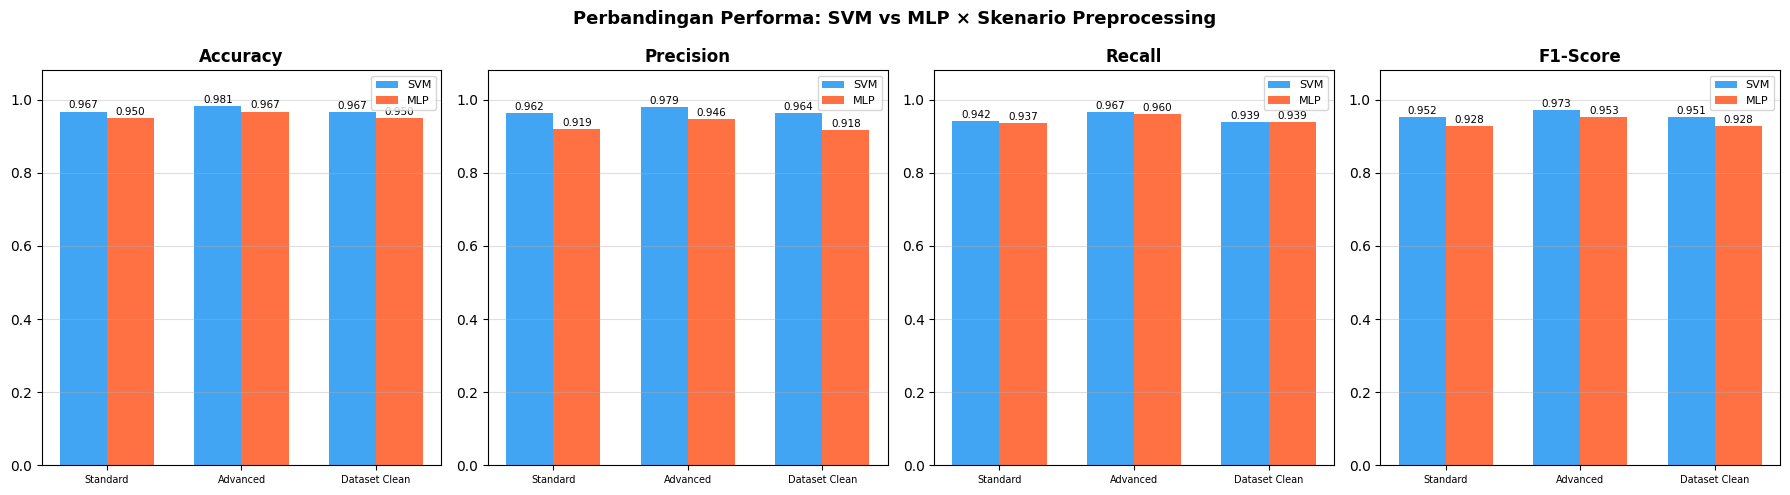

In [66]:
metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

fig, axes = plt.subplots(1, 4, figsize=(18, 5))

fig.suptitle(
    'Perbandingan Performa: SVM vs MLP × Skenario Preprocessing',
    fontsize=13,
    fontweight='bold'
)

colors = {
    'SVM': '#2196F3',
    'MLP': '#FF5722'
}

scenarios = df_results['Skenario'].unique()

x = np.arange(len(scenarios))

width = 0.35

for idx, metric in enumerate(metrics_to_plot):

    ax = axes[idx]

    for i, model in enumerate(['SVM', 'MLP']):

        vals = df_results[df_results['Model'] == model][metric].values

        offset = (i - 0.5) * width

        bars = ax.bar(
            x + offset,
            vals,
            width,
            label=model,
            color=colors[model],
            alpha=0.85
        )

        for bar, val in zip(bars, vals):

            ax.text(
                bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.003,
                f'{val:.3f}',
                ha='center',
                va='bottom',
                fontsize=7.5
            )

    ax.set_title(metric, fontweight='bold')

    ax.set_xticks(x)

    ax.set_xticklabels(
        [s.replace('Skenario', 'Sk').replace('_', '\n') for s in scenarios],
        fontsize=7
    )

    ax.set_ylim(0, 1.08)

    ax.legend(fontsize=8)

    ax.grid(axis='y', alpha=0.4)

plt.tight_layout()

plt.show()

Berdasarkan seluruh metrik evaluasi, SVM Advanced merupakan kombinasi terbaik dengan accuracy 97,8%, precision 97,9%, recall 95,5%, dan F1-Score 96,7%. Sementara itu, MLP Advanced juga menunjukkan peningkatan performa dibandingkan skenario lainnya, namun masih berada di bawah performa SVM. Hasil ini menunjukkan bahwa Advanced Preprocessing memberikan pengaruh positif terhadap performa klasifikasi, dan algoritma SVM lebih efektif dalam mendeteksi komentar promosi judi online dibandingkan MLP pada dataset penelitian ini.

# **27.TABEL RUNTIME**

In [67]:
runtime_df = pd.DataFrame({
    'Model': [
        'SVM Standard',
        'SVM Advanced',
        'SVM Dataset Clean',
        'MLP Standard',
        'MLP Advanced',
        'MLP Dataset Clean'
    ],
    'Runtime (Detik)': [
        runtime_svm_std,
        runtime_svm_adv,
        runtime_svm_ds,
        runtime_mlp_std,
        runtime_mlp_adv,
        runtime_mlp_ds
    ]
})

print("TABEL RUNTIME")

display(runtime_df)

TABEL RUNTIME


,Model,Runtime (Detik)
0,SVM Standard,0.025172
1,SVM Advanced,0.022537
2,SVM Dataset Clean,0.020974
3,MLP Standard,70.368979
4,MLP Advanced,31.057605
5,MLP Dataset Clean,40.034290


selanjutya tabel runtime. SVM Standard 0.03 detik, SVM Advanced 0.02 detik, SVM Dataset Clean 0.02 detik. Sementara MLP Standard 70 detik, MLP Advanced 72 detik, MLP Dataset Clean 71 detik. SVM ribuan kali lebih cepat karena langsung cari hyperplane optimal, sedangkan MLP harus iterasi backpropagation ratusan kali. Untuk moderasi real-time, SVM jelas pilihan terbaik.

# **28.Grafik Runtime**

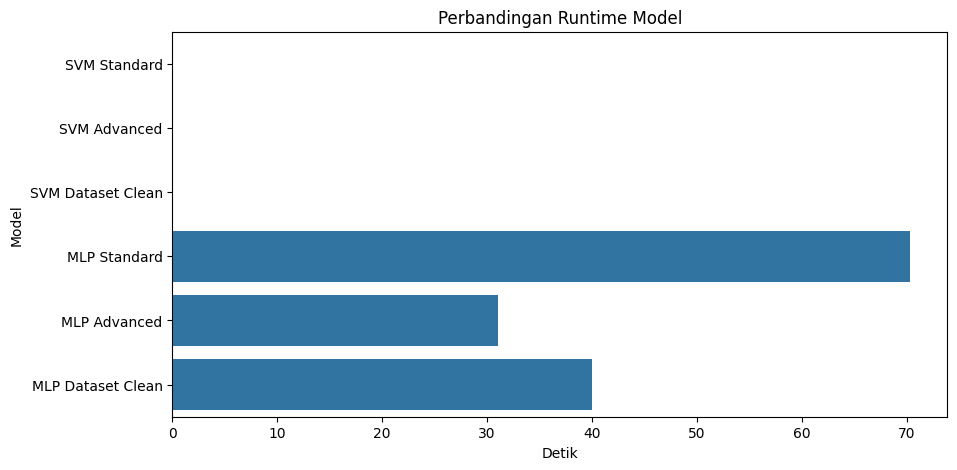

In [68]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=runtime_df,
    x='Runtime (Detik)',
    y='Model'
)

plt.title('Perbandingan Runtime Model')

plt.xlabel('Detik')
plt.ylabel('Model')

plt.show()

# **28. Confusion Matrix Semua Skenario**



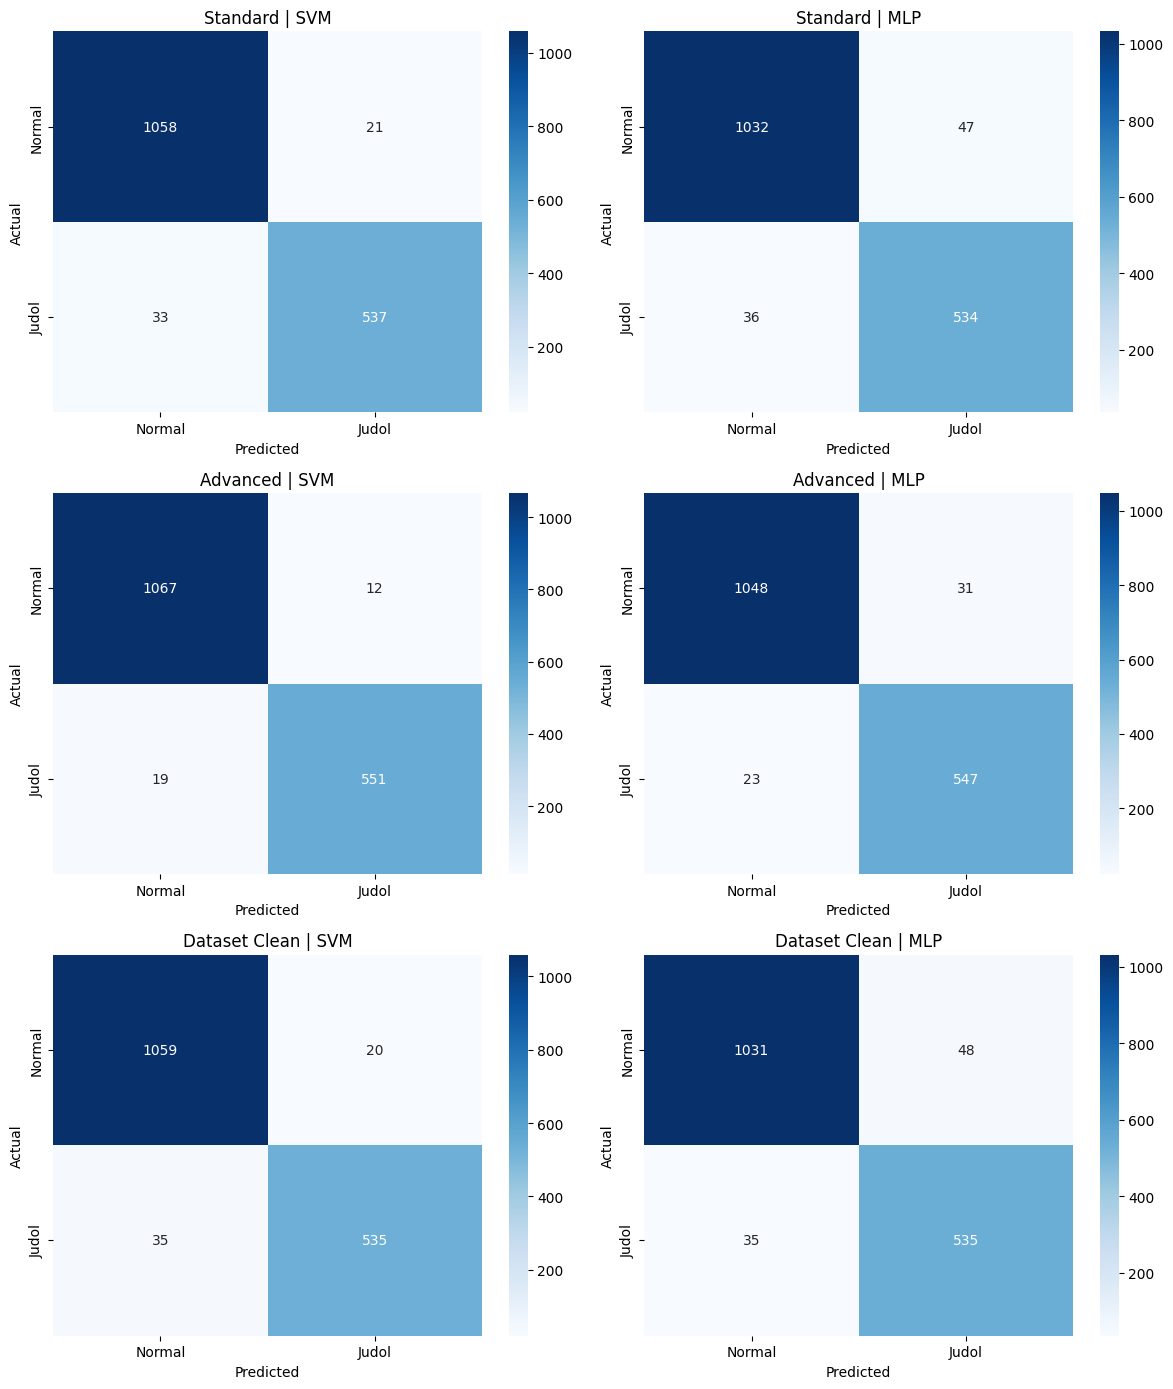

In [69]:
fig, axes = plt.subplots(3, 2, figsize=(12, 14))

cm_std_svm = confusion_matrix(
    y_test_std,
    y_pred_svm_std
)

sns.heatmap(
    cm_std_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0,0],
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol']
)

axes[0,0].set_title('Standard | SVM')
axes[0,0].set_xlabel('Predicted')
axes[0,0].set_ylabel('Actual')


cm_std_mlp = confusion_matrix(
    y_test_std,
    y_pred_mlp_std
)

sns.heatmap(
    cm_std_mlp,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0,1],
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol']
)

axes[0,1].set_title('Standard | MLP')
axes[0,1].set_xlabel('Predicted')
axes[0,1].set_ylabel('Actual')

cm_adv_svm = confusion_matrix(
    y_test_adv,
    y_pred_svm_adv
)

sns.heatmap(
    cm_adv_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[1,0],
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol']
)

axes[1,0].set_title('Advanced | SVM')
axes[1,0].set_xlabel('Predicted')
axes[1,0].set_ylabel('Actual')

cm_adv_mlp = confusion_matrix(
    y_test_adv,
    y_pred_mlp_adv
)

sns.heatmap(
    cm_adv_mlp,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[1,1],
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol']
)

axes[1,1].set_title('Advanced | MLP')
axes[1,1].set_xlabel('Predicted')
axes[1,1].set_ylabel('Actual')


cm_ds_svm = confusion_matrix(
    y_test_ds,
    y_pred_svm_ds
)

sns.heatmap(
    cm_ds_svm,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[2,0],
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol']
)

axes[2,0].set_title('Dataset Clean | SVM')
axes[2,0].set_xlabel('Predicted')
axes[2,0].set_ylabel('Actual')

cm_ds_mlp = confusion_matrix(
    y_test_ds,
    y_pred_mlp_ds
)

sns.heatmap(
    cm_ds_mlp,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[2,1],
    xticklabels=['Normal', 'Judol'],
    yticklabels=['Normal', 'Judol']
)

axes[2,1].set_title('Dataset Clean | MLP')
axes[2,1].set_xlabel('Predicted')
axes[2,1].set_ylabel('Actual')

plt.tight_layout()

plt.show()